In [1]:
#Cemile's code 

import numpy as np 
import matplotlib.pyplot as plt 


# Ex. 1:  (Lucht in een fietsband)
Als model gaan we uit van een deel van het volume van een fietsband die onder een druk van 10 bar staat. Laat zien dat het gemiddelde volume 
V
m
o
l
e
c
u
u
l
V 
molecuul
​
  ongeveer overeenkomt met een kubus met ribben van 
1.6
  
n
m
1.6nm is. Het antwoord gebruik je zo direct in de code hieronder.

In [2]:
P = 10 * 10**5 
n = 1
R = 8.31446261815324
T = 20 + 273.15

V = n*R*T / P

print(f"Het molaire volume V is {V:.4f} m^3")

N_A = 6.022*(10**23)
V_molecuul = V/N_A

print(f"Het volume van één molecuul is {V_molecuul}")

#Ribbe van een kubus 
ribbe = V_molecuul**(1/3)
print(f"De derdemachtswortel van Vmolecuul geeft {ribbe:.3f}, dit komt overeen met de ribbe van een kubus met 1.6 nm ")


Het molaire volume V is 0.0024 m^3
Het volume van één molecuul is 4.047467147976789e-27
De derdemachtswortel van Vmolecuul geeft 0.000, dit komt overeen met de ribbe van een kubus met 1.6 nm 


# Exercise 2 

 (Snelheid van een gasmolecuul)
Laat zien dat de snelheid van een gasmolecuul bij kamertemperatuur in twee dimensies ongeveer 
4
⋅
1
0
2
 
m
/
s
4⋅10 
2
 m/s is. Ook deze heb je hierna nodig.

In [3]:
m_gas_molecuul = 5.31*10**(-26)
m = m_gas_molecuul
k_B = 1.3806*10**(-23)

v = np.sqrt((2 * k_B * T)/m)

print(f"De snelheid van een deeltje in twee dimensies is {v:.2f} m/s. Dit is afgerond gelijk aan 4*10**2 m/s")

De snelheid van een deeltje in twee dimensies is 390.43 m/s. Dit is afgerond gelijk aan 4*10**2 m/s


# Exercise 3 

Info in de opdracht is te beperkt om hier een goede berekening voor te maken


# Exercise 4
Bekijk de waarde van DT. Hoe zorgt deze waaarde ervoor dat het onwaarschijnlijk is dat een botsing gemist wordt? Zet in het groene commentaar bij elke constante in welk eenheid deze wordt weergegeven.



In [4]:
#v = dx/dt 
#dt = dx/v 
#dx = ribbe?? 

dt = ribbe/v 
print(dt)

#ik snap niet wat ik hier moet berekenen

4.081763361373674e-12


In [22]:
BOX_SIZE_0 = 10                # Hoogte en lengte startvolume, m**3
N = 40                         # Aantal deeltjes
V_0 = 1                        # Startsnelheid van deeltjes, m/s
RADIUS = 0.3                   # Straal van moleculen, m
DT = 0.05 * RADIUS / V_0        # Tijdstap om geen botsing te missen, s 

# Particle class

Ons ParticleClass definieert van een deeltje de massa 
m
m, snelheid 
v
v, positie 
r
r, en straal 
R
R. De positie moet per tijdstap bepaald worden.

Nieuw aan ParticleClass zijn twee properties, nl. momentum en kin_energy. Een property is eigenlijk een variabele die samenhangt met de waarde van andere variabelen binnen de klasse. Om de interne consistentie te bewaren moet je de juiste waarde van deze variabele dus telkens afleiden en dat doe je met een functie. Zo geeft kin_energy de kinetische energie terug van het deeltje door die af te leiden van de variabelen m en v.

Buiten ParticleClass voegen we twee functies toe, die je ook al hebt gezien. De eerste heet collide_detection en detecteert of twee deeltjes onderling overlappen en dus botsen. De tweede heet particle_collision en berekent de nieuwe snelheden van de twee deeltjes ten gevolge van hun botsing.

In [6]:
# Maken van de class
class ParticleClass:
    def __init__(self, m, v, r, R):
        """ maakt een deeltje (constructor) """
        self.m = m                         
        self.v = np.array(v, dtype=float)  
        self.r = np.array(r, dtype=float)  
        self.R = R

    def update_position(self):
        """ verandert positie voor één tijdstap """
        self.r += self.v * DT 
            
    @property
    def momentum(self):
        return self.m * self.v
    
    @property
    def kin_energy(self):
        return 1/2 * self.m * np.dot(self.v, self.v)
    
def collide_detection(p1: ParticleClass, p2: ParticleClass) -> bool:
    """ Geeft TRUE als de deeltjes overlappen """
    dx = p1.r[0]-p2.r[0]
    dy = p1.r[1]-p2.r[1]
    rr = p1.R + p2.R
    return  dx**2+dy**2 < rr**2 
    #Note: np.linalg.norm(p1.r - p2.r) < (p1.R + p2.R) had ook gekund, maar is veel langzamer. Controleer zelf!

def particle_collision(p1: ParticleClass, p2: ParticleClass):
    """ past snelheden aan uitgaande van overlap """
    m1, m2 = p1.m, p2.m
    delta_r = p1.r - p2.r
    delta_v = p1.v - p2.v
    dot_product = np.dot(delta_r, delta_v)

    # Als deeltjes van elkaar weg bewegen dan geen botsing
    if dot_product >= 0: # '='-teken voorkomt ook problemen als delta_r == \vec{0}
        return
        
    distance_squared = np.dot(delta_r, delta_r) 
    # Botsing oplossen volgens elastische botsing in 2D
    p1.v -= 2 * m2 / (m1 + m2) * dot_product / distance_squared * delta_r
    p2.v += 2 * m1 / (m1 + m2) * dot_product / distance_squared * delta_r

In [7]:
def box_collision(particle: ParticleClass):
    ''' botsing met wanden geeft periodieke randvoorwaarden '''
    for i in range(2):
        if particle.r[i] > BOX_SIZE_0 / 2:
            particle.r[i] -= BOX_SIZE_0 
        elif particle.r[i] < -BOX_SIZE_0 / 2:
            particle.r[i] += BOX_SIZE_0

# Exercise 5 
Leg uit dat d.m.v. onderstaande code de deeltjes allemaal dezelfde snelheid hebben en uniform verdeeld zijn over de box.


Voor de snelheid geldt: $v = \sqrt{v_x^2 + v_y^2}$ 

Gegeven is het volgende:

$v_y = variabele * \sqrt{v_0^2 - v_x^2}$ waarbij variabele een -1 of 1 is.
$v_x = variabele2$

Hieruit volgt: 

$v = \sqrt{v_x^2 + (-1)^2 * (v_0^2 - v_x^2)} = \sqrt{v_x^2 + (1)^2 * (v_0^2 - v_x^2)}$

$= \sqrt{v_x^2 + v_0^2 - v_x^2}$ 

$= \sqrt{v_0^2}$ 

$=v_0$

Dus alle deeltjes hebben dezelfde snelheid

De deeltjes zijn uniform verdeeld over de box, omdat de positie wordt gekozen middels een uniforme verdeling (np.random.uniform).



In [8]:
def create_particles(particles):
    ''' Leegmaken en opnieuw aanmaken van deeltjes '''
    particles.clear
    for i in range(N):
        vx = np.random.uniform(-V_0, V_0)
        vy = np.random.choice([-1, 1]) * np.sqrt(V_0**2 - vx**2)        
        pos = np.random.uniform(-BOX_SIZE_0/2 + RADIUS, BOX_SIZE_0/2 - RADIUS, 2)
        particles.append(ParticleClass(m=1.0, v=[vx, vy], r=pos, R=RADIUS))

# Exercise 6
Leg uit hoe er in onderstaande code wordt voorkomen dat de botsing tussen twee deeltjes dubbel wordt uitgevoerd.

In de code worden twee loops gebruikt, waarbij de tweede loop begint bij i+1. Stel dat er 4 deeltjes zijn: 0, 1, 2 en 3, dan begint loop 1 bij deeltje 0. De tweede loop controleert deeltje 1, 2 en 3. De opties (0,1), (0,2), en (0,3) zijn dan al geweest. 

Bij de volgende iteratie is i gelijk aan 1. j begint dan bij i+1 = 2. De opties (1,2), (1,3) worden gecontroleerd. En zo gaat het door totdat alle deeltjes één keer zijn geweest. 

In [9]:
def handle_collisions(particles):
    """ alle onderlinge botsingen afhandelen voor deeltjes in lijst """
    num_particles = len(particles)
    for i in range(num_particles):
        for j in range(i+1, num_particles):
            if collide_detection(particles[i], particles[j]):
                particle_collision(particles[i], particles[j])

### Controleren op botsingen met wanden
Voor het bepalen of deeltjes botsen met de wanden maken we gebruik van de functie die we net hebben aangepast.

In [10]:
def handle_walls(particles):
    ''' botsing met wanden controleren voor alle deeltjes in volume '''
    for p in particles:
        box_collision(p)

### Integreren in tijdstap
Nu moeten we alle functies op de juiste manier combineren om de simulatie een tijdstap te laten maken:

In [11]:
def take_time_step(particles):
    for p in particles:
        p.update_position() #elk deeltje zet een stapje vooruit op basis van zijn huidige snelheid
        
    handle_collisions(particles) # nu de deeltjes verplaatst zijn, kunnen er twee tegen elkaar gebotst zijn (overlappen, dat wordt gecontroleerd en de nieuwe snelheden na de botsing worden berekend)
    handle_walls(particles)  # controle of er een deeltje buiten de randen van de doos is beland, zo ja dan worden deze weer teruggezet

    


### Uitvoeren simulatie en tonen resultaat
Zoals aangegeven, kunnen we een animatie maken van de positie en snelheid als functie van de tijd, maar we kunnen ook het eindresultaat tonen en interpreteren:

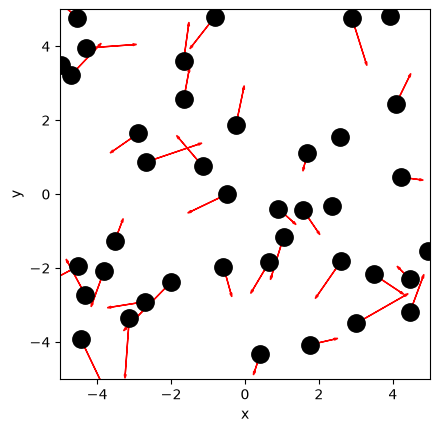

In [12]:
particles = []
create_particles(particles)
for i in range(100):
    take_time_step(particles)

plt.figure()
plt.xlabel('x')
plt.ylabel('y')
plt.gca().set_aspect('equal')
plt.xlim(-BOX_SIZE_0/2, BOX_SIZE_0/2)
plt.ylim(-BOX_SIZE_0/2, BOX_SIZE_0/2)

for p in particles:
    plt.plot(p.r[0], p.r[1], 'k.', ms=25)
    plt.arrow(p.r[0], p.r[1], p.v[0], p.v[1], 
              head_width=0.05, head_length=0.1, color='red')
plt.show()

### Toevoegen animatie
Zoals gezegd: het kost veel meer rekenkracht om een animatie te maken over de tijd. Soms kan het wel helpen om te zien of de simulatie aan alle verwachtingen voldoet.

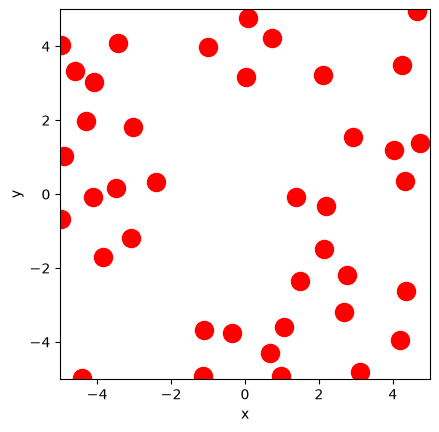

In [13]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xlim(-BOX_SIZE_0/2, BOX_SIZE_0/2)
ax.set_ylim(-BOX_SIZE_0/2, BOX_SIZE_0/2)
ax.set_aspect('equal')
dot, = ax.plot([], [], 'ro', ms=13);

def init():
    dot.set_data([], [])
    return dot,

def update(frame):
    take_time_step(particles)
    dot.set_data([p.r[0] for p in particles], [p.r[1] for p in particles])
    return dot,

ani = FuncAnimation(fig, update, frames=100, init_func=init, blit=True, interval=50)
HTML(ani.to_jshtml())

### Controle code
Om te controleren of onze code werkt passen we nu de code aan.

# Exercise 7
Voeg aan de simulatie een regel toe die voor elke tijdstap bepaalt wat de totale kinetische energie is voor alle deeltjes en neem deze waarde op in een array die bij elke tijdstap met één element groeit in lengte. Maak vervolgens een plot van de totale kinetische energie als functie van de tijd gedurende een simulatie van 100 tijdstappen.

<function matplotlib.pyplot.show(close=None, block=None)>

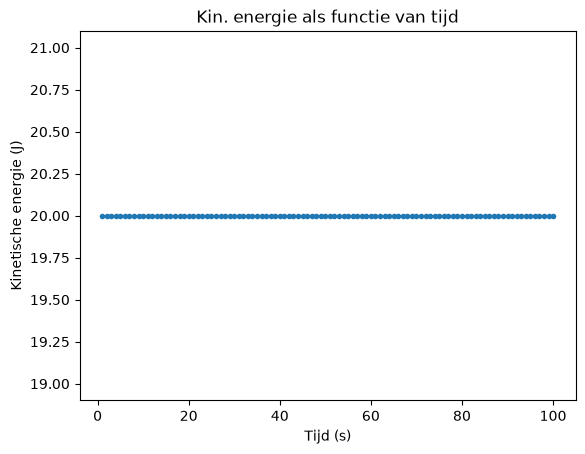

In [14]:
# plotten van kinetische energie als functie van tijd
%matplotlib inline


particles = []
energy_tot = []
create_particles(particles)
for i in range(100):
    take_time_step(particles)
    energy_tot = np.append(energy_tot, np.sum([p.kin_energy for p in particles]))
    # voeg de som van de kinetische energie in deze stap toe aan energy_tot 

# plot de figuur van de kinetische energie als functie van de tijd. 
### YOUR CODE HERE ###

x_tijd = np.linspace(1,100,100)
y = energy_tot 

plt.figure()
plt.plot(x_tijd,y, '.')
plt.xlabel("Tijd (s)")
plt.ylabel("Kinetische energie (J)")

plt.title("Kin. energie als functie van tijd")
plt.show

# Exercise 8 
Als je heel nauwkeurig naar de waarde voor de totale kinetische energie kijkt, dan varieert deze toch. Zoom hiervoor goed in op de as voor de energie. Op welke energieschaal gebeurt dit en is de oorzaak?


De afwijkingen zijn te zien vanaf een schaal van 20 $\pm 1 \cdot 10^{-13} J$. Python gebruikt voor float de IEEE 754-standaard (de internationale standaard voor double precision floating-point getallen). Een 64-bit float gebruikt 52 bits voor het getal achter de komma. De episilon $\epsilon$ (het laagste getal dat je bij 1 kunt optellen, waarbij 1 + $\epsilon$ > 1) is gelijk aan $\frac{1}{2^{52}} \approx 2{,}22 \cdot 10^{-16}$.

20 ligt tussen $2^4 en 2^5$.

Stapgrootte rond $2^4 \cdot \epsilon \approx 3{,}55 \cdot 10^{-15}$

Voor 40 deeltjes geldt:
$40 \cdot 3{,}55 \cdot 10^{-15} \approx 1{,}4 \cdot 10^{-13}$. Dit is in de ordergrootte van de gevonden afwijking. 

<function matplotlib.pyplot.show(close=None, block=None)>

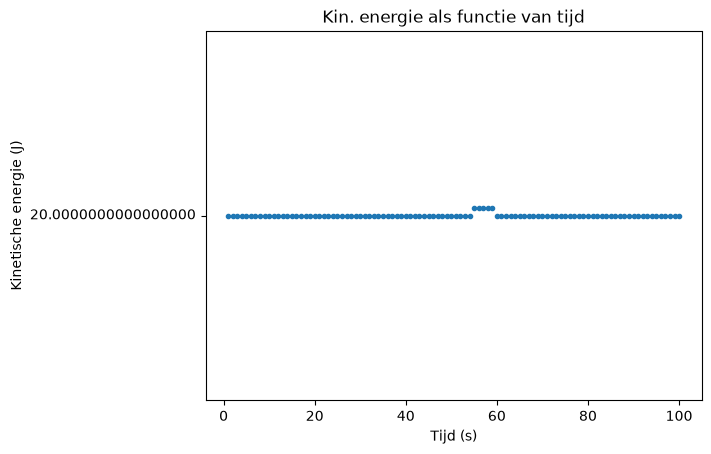

In [15]:
plt.figure()
plt.plot(x_tijd,y, '.')
plt.xlabel("Tijd (s)")
plt.ylabel("Kinetische energie (J)")
plt.ylim(19.9999999999999,20.0000000000001)

plt.title("Kin. energie als functie van tijd")
plt.show

Voor simulaties waarbij de kans op botsingen heel groot is (richting vloeistof), is er een handige methode om de snelheid van je simulatie op te voeren. In onderstaande code wordt daar een voorbeeld van gegeven.

In [16]:
def handle_collisions(particles):
    ignore_list = []
    for i, p1 in enumerate(particles):
        if p1 in ignore_list:
            continue
        for j, p2 in enumerate(particles):
            if p1 is p2:
                continue                
            if collide_detection(particles[i], particles[j]):
                particle_collision(particles[i], particles[j])
                ignore_list.append(p2)

### Exercise 9.1
Leg uit wat deze code precies doet 

Voor botsingen wordt per tijdstap een ignore_list aangemaakt. De code loopt alle deeltjes (p1) langs. Als een p1 zich al in de ignore_list bevindt, wordt dit deeltje niet gecontroleerd op botsingen. Als p1 zich niet in de ignore_list bevindt, wordt dit deeltje met deeltje 2 (p2) vergeleken, mits p2 niet hetzelfde deeltje is al p1. Als er een botsing wordt gedetecteerd, wordt de snelheid van beide deeltjes aangepast en p2 aan de ignore_list toegevoegd. In de volgende iteratie wanneer p2 aan de beurt is als p1, wordt dit deeltje niet voor een tweede keer gecontroleerd. 

### Exercise 9.2
Maak een script waarbij twee deeltjes met dezelfde (absolute) snelheid op een derde deeltje afbewegen en tegelijk zouden botsen.

Laat zien dat ‘slechts’ twee deeltjes een interactie met elkaar aan gaan.
```
Zoals hieronder te zien is, lijken de linker en rechter deeltjes tegelijkertijd te botsen, maar het rechter deeltje (p1) is als eerst aangemaakt en loopt als eerste door de loop. Dit deeltje botst tegen het middeltjes deeltje (p2) waarna dit een klein stukje naar links wordt verplaatst. Vervolgens wordt de botsing p2-p3 verwerkt. Er zijn dus twee botsingen per keer: p1-p2 en daarna p2-p3
```


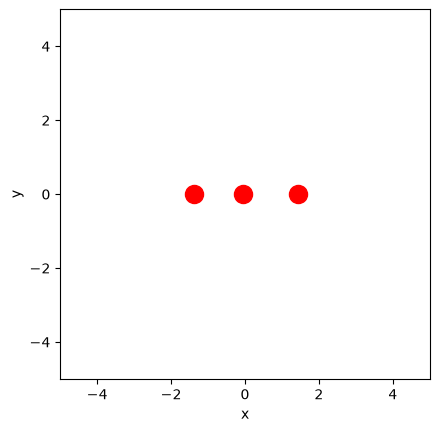

In [28]:

DT = 0.15 * RADIUS / V_0        # Tijdstap om geen botsing te missen, s 

# aanmaken deeltjes 
p1 = ParticleClass(m=1, v=(1, 0),  r=(-1.5, 0), R=RADIUS)
p2 = ParticleClass(m=1, v=(-1, 0), r=(1.5, 0),  R=RADIUS)
p3 = ParticleClass(m=1, v=(0, 0),  r=(0, 0),    R=RADIUS)

deeltjes = [p1, p2, p3]


tijdstappen = 200

posities_p1 = np.zeros((tijdstappen, 2))
posities_p2 = np.zeros((tijdstappen, 2))
posities_p3 = np.zeros((tijdstappen, 2))
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xlim(-BOX_SIZE_0/2, BOX_SIZE_0/2)
ax.set_ylim(-BOX_SIZE_0/2, BOX_SIZE_0/2)
ax.set_aspect('equal')
dot, = ax.plot([], [], 'ro', ms=13);

def init():
    dot.set_data([], [])
    return dot,

def update(frame):
    take_time_step(deeltjes)
    dot.set_data(
        [p.r[0] for p in deeltjes], [p.r[1] for p in deeltjes])
    return dot,

ani = FuncAnimation(fig, update, frames=tijdstappen, init_func=init, blit=True, interval=50)
HTML(ani.to_jshtml())

### Exercise 9.3
Leg uit waarom dat een acceptabele benadering is wanneer je veel deeltjes botsingen per tijdseenheid hebt.

```
Behoud van energie en impuls blijft kloppen. Het maakt niet uit of een botsing in één keer of in twee snelle stapjes wordt berekend.
```

Voor wie een uitdaging wil: maak een grafiek met het aantal botsingen per tijdseenheid. Dit om bovenstaande benadering verder te verantwoorden.

# Brownian motion

In [29]:
import numpy as np
import matplotlib.pyplot as plt

In [30]:
# Maken van de ParticleClass

class ParticleClass:
    # Het maken van het deeltje
    def __init__(self, m, v, r, R, c):
        self.m = m                         
        self.v = np.array(v, dtype=float)  
        self.r = np.array(r, dtype=float)  
        self.R = R  
        self.c = c

    # Het updaten van de positie, eventueel met zwaartekracht
    def update_position(self):
        self.r += self.v * dt #+ 1/2 * a * dt**2  
              
    # Harde wand
    def boxcollision(self):
        if abs(self.r[0]) + self.R > Box_length: 
            self.v[0] = -self.v[0]                                  # Omdraaien van de snelheid
            self.r[0] = np.sign(self.r[0]) * (Box_length - self.R)  # Zet terug net binnen box                 
        if abs(self.r[1]) + self.R > Box_length: 
            self.v[1] = -self.v[1]     
            self.r[1] = np.sign(self.r[1]) * (Box_length - self.R) 
            
    @property
    def momentum(self):
        return self.m * self.v
    
    @property
    def kin_energy(self):
        return 1/2 * self.m * np.dot(self.v, self.v)

In [32]:
# Aanmaken van de randvoorwaarden en initiele condities
Box_size_0 = 10
Box_length_0 = Box_size_0/2
Box_length = Box_length_0     # De grootte van de box kan wijzigen!

# Particles
dt = 0.1
particles = []
N = 40
v_0 = 1

dt = 0.04

# Aanmaken van deeltjes
for i in range(N-1):
    vx = np.random.uniform(-v_0,v_0)
    vy = np.random.choice([-1, 1])*np.sqrt(v_0**2-vx**2)        
    pos = Box_length_0*np.random.uniform(-1,1,2)
    particles.append(ParticleClass(m=1.0, v=[vx, vy], r = pos, R=.5,c='blue')) 

#Aanmaken pol
particles.append(ParticleClass(m=20.0, v=[0, 0], r = [0, 0], R=.5,c='red')) 


### Exercise 10 
Leg uit wat er in de laatste regel van bovenstaande script gebeurt. Voeg voor deze regel goede metadata toe.

``` 
Eerst worden er 40 kleine deeltjes (m = 1.0) aangemaakt in de for loop. Vervolgens wordt een deeltje aangemaakt met een massa van m=20.0, welke een pol (of een ander zwaarder deeltje) simuleert.
```